In [1]:
from plantdata import load_classes, read_manifest
from pathlib import Path
from training import run_experiment

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

FINAL = dict(depth=18, freeze="none", augment=True, optimiser="sgd", lr=1e-3, weight_decay=1e-4,
             batch_size=32, epochs=15, patience=5, class_weights="none", dropout=0.2)
for run_id, seed in [("R21", 1), ("R22", 2)]:
    run_experiment(run_id, f"FINAL setting (= R15), seed {seed}", manifest, CACHE_DIR, CLASS_IDS, CROPS,
                   crop_mask, seed=seed, **FINAL)

R21: FINAL setting (= R15), seed 1 | 11,186,772 trainable weights
  epoch  1 | lr 1.00e-03 | train loss 0.366 acc 0.881 | val_lab F1-16 0.940 | val_wild F1-16 0.462 * | 142 s
  epoch  2 | lr 9.89e-04 | train loss 0.112 acc 0.965 | val_lab F1-16 0.964 | val_wild F1-16 0.451 | 33 s
  epoch  3 | lr 9.57e-04 | train loss 0.078 acc 0.975 | val_lab F1-16 0.971 | val_wild F1-16 0.471 * | 37 s
  epoch  4 | lr 9.05e-04 | train loss 0.063 acc 0.980 | val_lab F1-16 0.973 | val_wild F1-16 0.463 | 34 s
  epoch  5 | lr 8.35e-04 | train loss 0.049 acc 0.984 | val_lab F1-16 0.970 | val_wild F1-16 0.450 | 34 s
  epoch  6 | lr 7.50e-04 | train loss 0.044 acc 0.986 | val_lab F1-16 0.977 | val_wild F1-16 0.449 | 34 s
  epoch  7 | lr 6.55e-04 | train loss 0.039 acc 0.988 | val_lab F1-16 0.980 | val_wild F1-16 0.457 | 34 s
  epoch  8 | lr 5.52e-04 | train loss 0.036 acc 0.988 | val_lab F1-16 0.979 | val_wild F1-16 0.458 | 34 s
  early stop: no val_wild improvement for 5 epochs
  best: epoch 3, val_wild F1-1

In [2]:
import pandas as pd

s = pd.read_csv("results/runs_summary.csv").set_index("run_id")
final = s.loc[["R15", "R21", "R22"], ["seed", "best_epoch", "val_lab_f1_16", "val_wild_f1_16",
                                      "val_wild_f1_20", "val_wild_late_blight_recall", "train_minutes"]]
display(final.round(3))
final.drop(columns="seed").agg(["mean", "std"]).round(3)

,seed,best_epoch,val_lab_f1_16,val_wild_f1_16,val_wild_f1_20,val_wild_late_blight_recall,train_minutes
run_id,,,,,,,
R15,42,2,0.954,0.474,0.490,0.802,5.168
R21,1,3,0.971,0.471,0.483,0.719,6.394
R22,2,1,0.946,0.469,0.481,0.702,4.216


,best_epoch,val_lab_f1_16,val_wild_f1_16,val_wild_f1_20,val_wild_late_blight_recall,train_minutes
mean,2.0,0.957,0.471,0.484,0.741,5.259
std,1.0,0.013,0.003,0.005,0.054,1.092


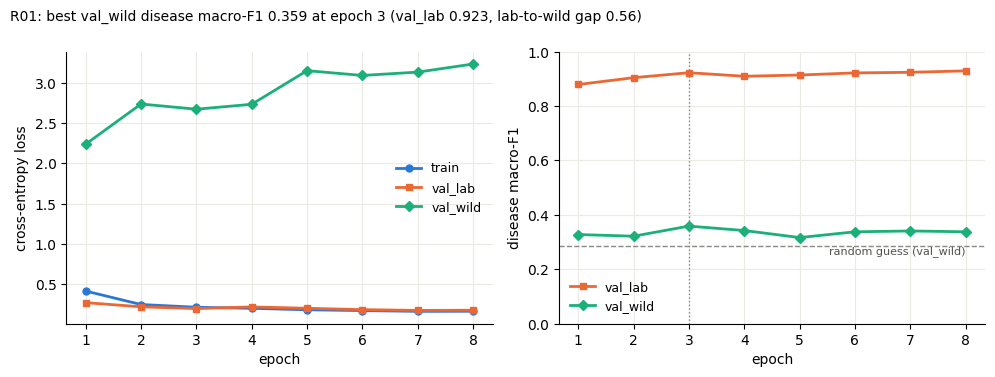

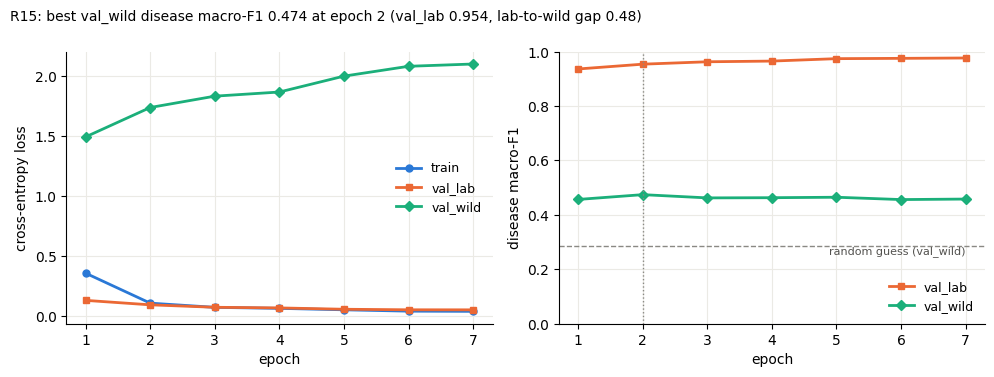

In [3]:
from plots import plot_history

plot_history("R01");   # initial ANN
plot_history("R15");   # final ANN (the deployed model)